In [1]:
import mne
from pathlib import Path
import numpy as np
import neural_mi as nmi
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
import random
import seaborn as sns
import sys
from pathlib import Path

# Add the parent directory (which contains "src") to the Python path
sys.path.append(str(Path().resolve().parent / "src"))

from run_trialwise_mi import run_trialwise_mi

In [ ]:
data_path = Path("../data/raw/P1-20251027T182958Z-1-001/P1/")

file_path = data_path / "binepochs filtered ICArej P1AvgBOS2.set"

epochs = mne.io.read_epochs_eeglab(file_path)

auditory_epochs = epochs[::2]

auditory_epochs_norm = zscore_across_channels_per_trial(auditory_epochs.get_data())

channels_of_interest = ['C3', 'T7']
auditory_subset = auditory_epochs.copy().pick_channels(channels_of_interest).get_data()

x_trials_scaled = auditory_subset[:, 0, :] * 1e5 # C3
y_trials_scaled = auditory_subset[:, 1, :] * 1e5 # T7

print(auditory_subset.shape)
print(x_trials_scaled.shape)
print(y_trials_scaled.shape)


Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...


C:\Users\Rinta\AppData\Local\Temp\ipykernel_40392\2765415441.py:5: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(file_path)


Not setting metadata
120 matching events found
No baseline correction applied
0 projection items activated
Ready.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
(60, 2, 1792)
(60, 1792)
(60, 1792)


In [2]:
# Cross-channel normalization at the epoch-level

import mne
import numpy as np

# ================================================================
# 1. Load data from EEGLAB .set file
# ================================================================
data_path = Path("../data/raw/P1-20251027T182958Z-1-001/P1/")

file_path = data_path / "binepochs filtered ICArej P1AvgBOS2.set"

epochs = mne.io.read_epochs_eeglab(file_path)

epochs = epochs[::2]

print("Loaded data with shape:", epochs.get_data().shape)
print("Number of epochs:", len(epochs))
print("Sampling rate:", epochs.info["sfreq"])

# ================================================================
# 2. Convert to NumPy array → shape (trials, channels, time)
# ================================================================
data = epochs.get_data()
print("Numpy array shape:", data.shape)

# ================================================================
# 3. Z-score across channels per trial
#    For each trial (C x T matrix), normalize across channel axis
# ================================================================
def zscore_across_channels_per_trial(data):
    # data shape: (trials, channels, times)
    means = data.mean(axis=1, keepdims=True)     # (trials, 1, times)
    stds  = data.std(axis=1, keepdims=True)      # (trials, 1, times)
    stds[stds == 0] = 1.0
    return (data - means) / stds

data_norm = zscore_across_channels_per_trial(data)
print("Normalized data shape:", data_norm.shape)

# ================================================================
# 4. Inspect channel list to confirm indices
# ================================================================
ch_names = epochs.ch_names
print("\nAvailable channels:")
for i, ch in enumerate(ch_names):
    print(f"{i:2d} : {ch}")

# ================================================================
# 5. Select C3 and T7 channels
# ================================================================
channels_of_interest = ["C3", "T7"]

def get_channel_indices(ch_names, selected_names):
    idx = []
    for nm in selected_names:
        if nm not in ch_names:
            raise ValueError(f"Channel {nm} not found.")
        idx.append(ch_names.index(nm))
    return idx

selected_idx = get_channel_indices(ch_names, channels_of_interest)
print("\nSelected channels:", channels_of_interest)
print("Channel indices:", selected_idx)

# Extract them → remains (trials, 2, times)
subset = data_norm[:, selected_idx, :]

# Convert to (2, trials, times) for MI library
mi_input = subset.transpose(1, 0, 2)

x_trials_norm = mi_input[0, :, :]
y_trials_norm = mi_input[1, :, :]

print("\nFinal MI-ready array shape:", mi_input.shape)
print("Expected: (2, n_trials, n_times)")
print(x_trials_norm.shape)
print(y_trials_norm.shape)


Extracting parameters from c:\Users\Rinta\Documents\Classes\PSYC 4745\Research Project\CISI Repo\Phys-Cog-CISI-Group\notebooks\..\data\raw\P1-20251027T182958Z-1-001\P1\binepochs filtered ICArej P1AvgBOS2.set...
Not setting metadata
120 matching events found


C:\Users\Rinta\AppData\Local\Temp\ipykernel_43764\3176439589.py:13: RuntimeWarning: At least one epoch has multiple events. Only the latency of the first event will be retained.
  epochs = mne.io.read_epochs_eeglab(file_path)


No baseline correction applied
0 projection items activated
Ready.
Loaded data with shape: (60, 32, 1792)
Number of epochs: 60
Sampling rate: 512.0
Numpy array shape: (60, 32, 1792)
Normalized data shape: (60, 32, 1792)

Available channels:
 0 : AF7
 1 : FPZ
 2 : AF8
 3 : AF3
 4 : AF4
 5 : F3
 6 : FZ
 7 : F4
 8 : FC5
 9 : FC1
10 : FC2
11 : FC6
12 : T7
13 : C3
14 : Cz
15 : C4
16 : T8
17 : TP7
18 : CP3
19 : CP1
20 : CPZ
21 : CP2
22 : CP4
23 : TP8
24 : P5
25 : P1
26 : P2
27 : P6
28 : POz
29 : O1
30 : Oz
31 : O2

Selected channels: ['C3', 'T7']
Channel indices: [13, 12]

Final MI-ready array shape: (2, 60, 1792)
Expected: (2, n_trials, n_times)
(60, 1792)
(60, 1792)


(1792,) (1792,) (1792,)


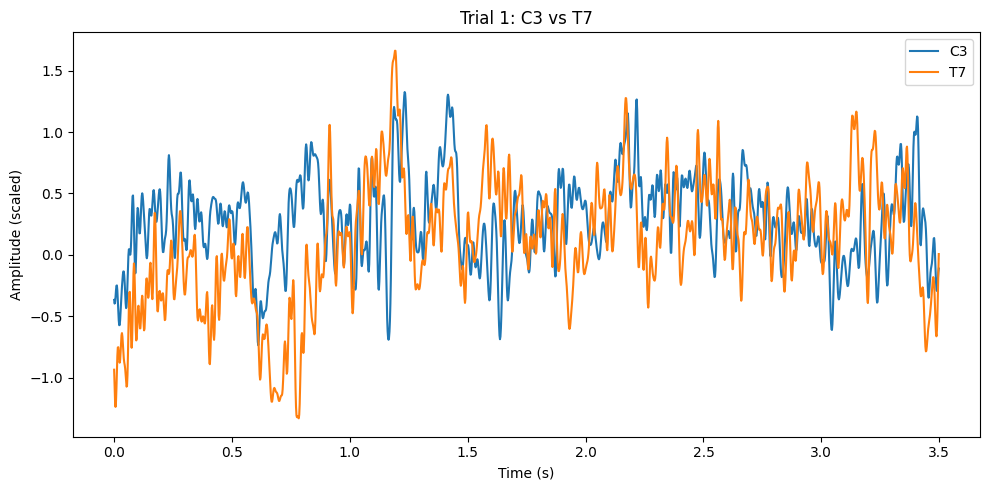

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Assume x_trials and y_trials are (n_trials, n_times)
trial = 0
sfreq = 512
t = np.arange(x_trials_scaled.shape[1]) / sfreq  # time in seconds

x_sig = x_trials_scaled[trial]
y_sig = y_trials_scaled[trial]

print(t.shape, x_sig.shape, y_sig.shape)

plt.figure(figsize=(10, 5))
plt.plot(t, x_sig, label="C3")
plt.plot(t, y_sig, label="T7")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (scaled)")
plt.title(f"Trial {trial+1}: C3 vs T7")
plt.legend()
plt.tight_layout()
plt.show()

(1792,) (1792,) (1792,)


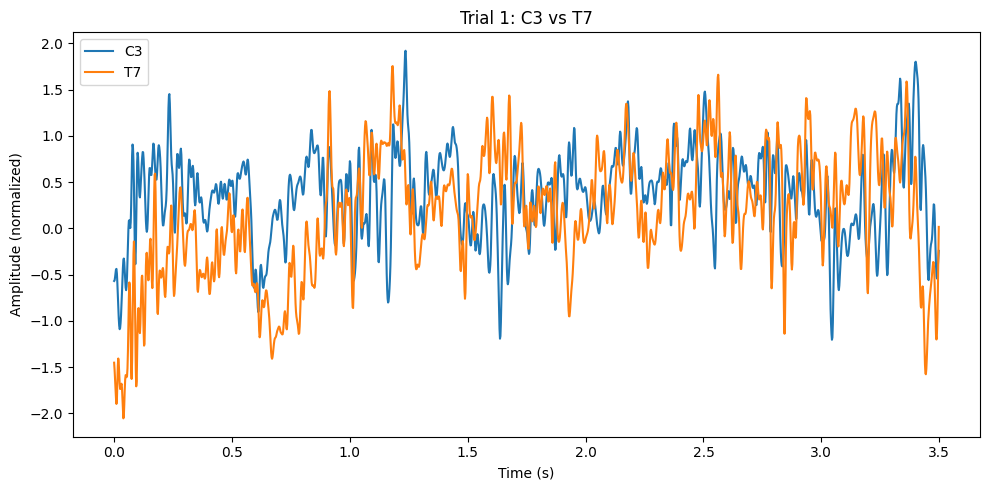

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Assume x_trials and y_trials are (n_trials, n_times)
trial = 0
sfreq = 512
t = np.arange(x_trials_norm.shape[1]) / sfreq  # time in seconds

x_sig = x_trials_norm[trial]
y_sig = y_trials_norm[trial]

print(t.shape, x_sig.shape, y_sig.shape)

plt.figure(figsize=(10, 5))
plt.plot(t, x_sig, label="C3")
plt.plot(t, y_sig, label="T7")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (normalized)")
plt.title(f"Trial {trial+1}: C3 vs T7")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import sys
from pathlib import Path

# Add the parent directory (which contains "src") to the Python path
sys.path.append(str(Path().resolve().parent / "src"))

from run_trialwise_mi import run_trialwise_mi

summary_df, curves, curves_shuf = run_trialwise_mi(
    x_trials=x_trials_scaled,
    y_trials=y_trials_scaled,
    label="Auditory",
    ch_pair=("C3", "T7"),
    resume=True
)

# Results: pretty much the same as previous results (not significant)

In [ ]:
# Next steps
# Normalize across channels per epoch
# Demeaning window sizes (512 to 1024)
# Averaging across multiple trials (all 60 or first 20 vs. last 20)

🔁 Resuming from 59 completed trials.


Trials (Auditory):   0%|          | 0/60 [00:00<?, ?it/s]

(1792,) (1792,) (1792,)


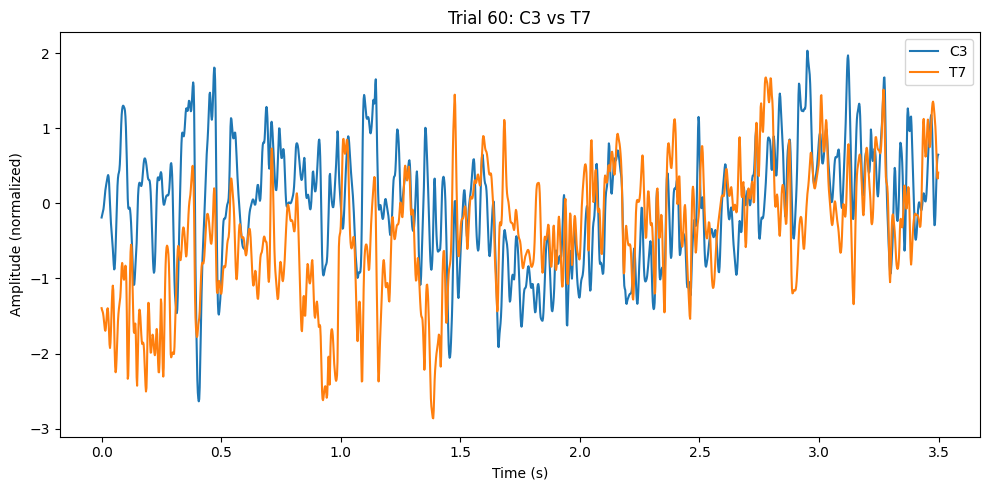

2025-11-18 09:33:34 - neural_mi - INFO - Detected sweep over processor or lag parameters. Deferring data processing to workers.
2025-11-18 09:33:34 - neural_mi - INFO - Preparing 30 tasks for lag analysis.
2025-11-18 09:33:34 - neural_mi - INFO - Starting parameter sweep sequentially (n_workers=1)...


Sequential Sweep Progress:   0%|          | 0/30 [00:00<?, ?it/s]

Run lag-600_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

Run lag-560_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

Run lag-520_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

...

Run lag480_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

Run lag520_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

Run lag560_combo0:   0%|          | 0/500 [00:00<?, ?it/s]

Trials (Auditory): 100%|██████████| 60/60 [13:07<00:00, 13.13s/it]

✅ Completed 60 successful trials out of 60


In [12]:
import sys
from pathlib import Path

# Add the parent directory (which contains "src") to the Python path
sys.path.append(str(Path().resolve().parent / "src"))

from run_trialwise_mi import run_trialwise_mi

summary_df, curves, curves_shuf = run_trialwise_mi(
    x_trials=x_trials_norm,
    y_trials=y_trials_norm,
    label="Auditory",
    ch_pair=("C3", "T7"),
    resume=True
)

In [6]:
mi_data = np.load(mi_path, allow_pickle=True)

print("\nType:", type(mi_data))
print("Dtype:", mi_data.dtype)
print("Shape:", mi_data.shape)

# If it's an object array, inspect first element
if mi_data.dtype == object:
    print("\nFirst element type:", type(mi_data[0]))
    print("First element keys (if dict):", getattr(mi_data[0], "keys", lambda: "not a dict")())
    print("First element:", mi_data[0])



Type: <class 'numpy.ndarray'>
Dtype: object
Shape: (60, 2, 30)

First element type: <class 'numpy.ndarray'>
First element keys (if dict): not a dict
First element: [[-600 -560 -520 -480 -440 -400 -360 -320 -280 -240 -200 -160 -120 -80
  -40 0 40 80 120 160 200 240 280 320 360 400 440 480 520 560]
 [4.430035062237156 4.35622836365408 4.244259058809849 3.163822426288176
  4.211088077007335 3.5243138849005025 3.6349833448695126
  4.303652579354716 3.448489141892202 3.949719851115694 3.573501610977869
  3.1395133665193216 3.825596188369686 4.122814541798982
  3.630118987572509 3.9048041740857595 3.5341960080190793
  3.79732224056784 4.041845453738073 4.088952533705301 4.280229918168408
  3.7791281959330636 3.814091924888171 3.843936418257696
  3.9446377637826977 4.036848669799904 4.272786509039066
  4.246429135898436 4.192088809601219 4.439506490785472]]


Loaded object array shape: (60, 2, 30)
lags shape: (30,)
MI curves shape: (60, 30)


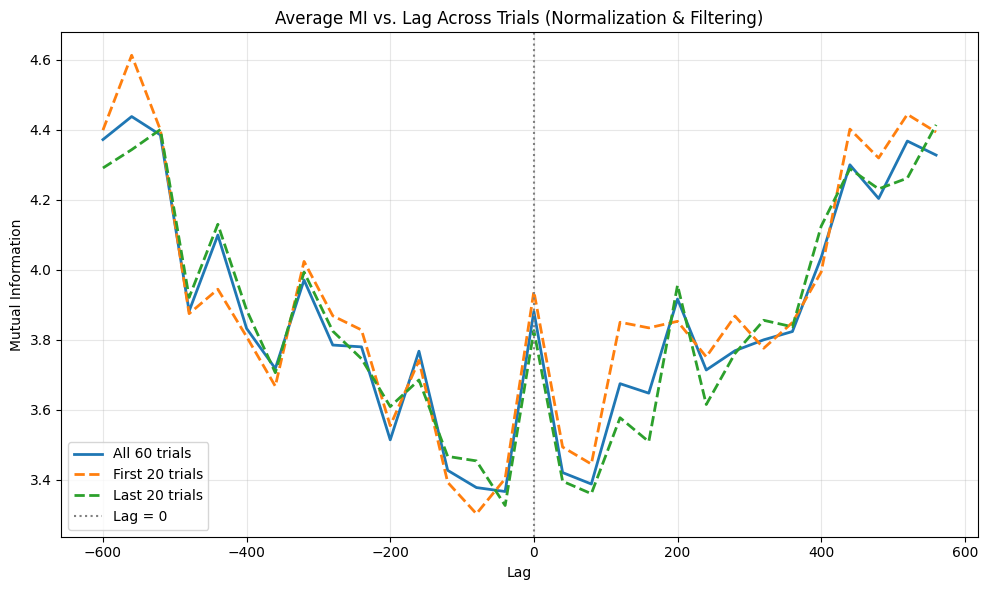

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# 1. Load your object-array .npy file
# ================================================================
mi_path = "../results/trialwise_mi_results_trash/auditory_C3_T7/all_curves.npy"
mi_obj = np.load(mi_path, allow_pickle=True)

print("Loaded object array shape:", mi_obj.shape)  # expected (60, 2, 30)

# ================================================================
# 2. Extract lags and MI curves
# ================================================================
lags = mi_obj[0][0].astype(int)        # Row 0 = lag values
mi_curves = np.array([entry[1] for entry in mi_obj])  # Row 1 = MI values

print("lags shape:", lags.shape)       # (30,)
print("MI curves shape:", mi_curves.shape)  # (60, 30)

# ================================================================
# 3. Compute averages
# ================================================================
mi_all_avg = mi_curves.mean(axis=0)

# First 20 and last 20 (ensure you actually have 60 trials)
mi_first20 = mi_curves[:20].mean(axis=0)
mi_last20  = mi_curves[-20:].mean(axis=0)

# ================================================================
# 4. Plot the averaged MI curves
# ================================================================
plt.figure(figsize=(10,6))

plt.plot(lags, mi_all_avg, label="All 60 trials", linewidth=2)
plt.plot(lags, mi_first20, "--", label="First 20 trials", linewidth=2)
plt.plot(lags, mi_last20, "--", label="Last 20 trials", linewidth=2)

plt.axvline(0, color="gray", linestyle=":", label="Lag = 0")

plt.title("Average MI vs. Lag Across Trials (Normalization & Filtering)")
plt.xlabel("Lag")
plt.ylabel("Mutual Information")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



Loaded object array shape: (60, 2, 30)
lags shape: (30,)
MI curves shape: (60, 30)


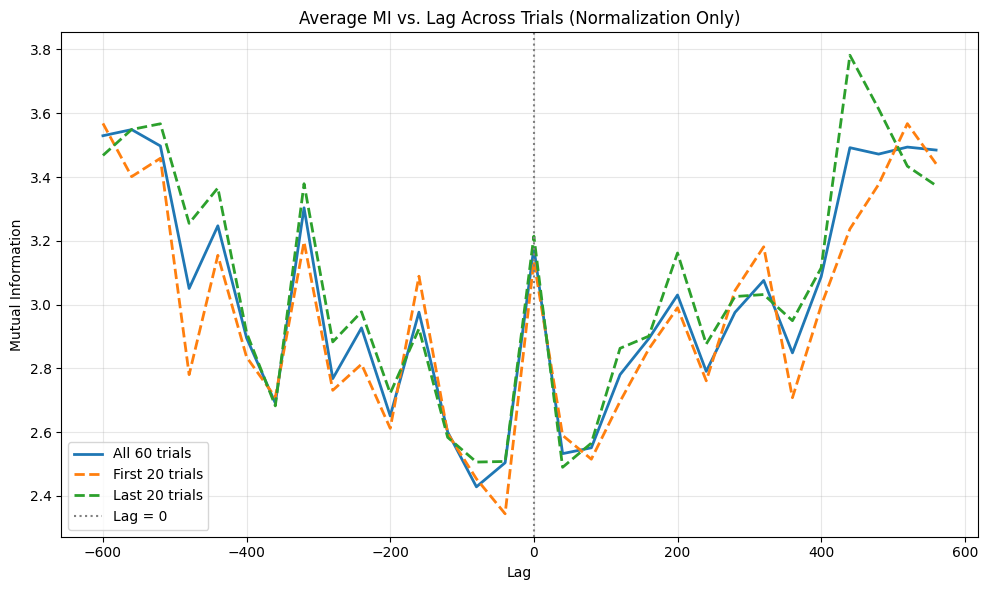

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ================================================================
# 1. Load your object-array .npy file
# ================================================================
mi_path = "../results/trialwise_mi_results/auditory_C3_T7/all_curves.npy"
mi_obj = np.load(mi_path, allow_pickle=True)

print("Loaded object array shape:", mi_obj.shape)  # expected (60, 2, 30)

# ================================================================
# 2. Extract lags and MI curves
# ================================================================
lags = mi_obj[0][0].astype(int)        # Row 0 = lag values
mi_curves = np.array([entry[1] for entry in mi_obj])  # Row 1 = MI values

print("lags shape:", lags.shape)       # (30,)
print("MI curves shape:", mi_curves.shape)  # (60, 30)

# ================================================================
# 3. Compute averages
# ================================================================
mi_all_avg = mi_curves.mean(axis=0)

# First 20 and last 20 (ensure you actually have 60 trials)
mi_first20 = mi_curves[:20].mean(axis=0)
mi_last20  = mi_curves[-20:].mean(axis=0)

# ================================================================
# 4. Plot the averaged MI curves
# ================================================================
plt.figure(figsize=(10,6))

plt.plot(lags, mi_all_avg, label="All 60 trials", linewidth=2)
plt.plot(lags, mi_first20, "--", label="First 20 trials", linewidth=2)
plt.plot(lags, mi_last20, "--", label="Last 20 trials", linewidth=2)

plt.axvline(0, color="gray", linestyle=":", label="Lag = 0")

plt.title("Average MI vs. Lag Across Trials (Normalization Only)")
plt.xlabel("Lag")
plt.ylabel("Mutual Information")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

